# Intensity detection — multi-scale windows, templates, thresholds and NMS

This notebook compares Histogram and Entropy on all 120 validation images, including 24 negatives. Test is untouched. The current run is a **development baseline**, with thresholds selected on this same validation split, not an unbiased final performance estimate.

**Configuration:** 12 windows (widths 8,16,24,32,48,64; width:height 1:1 and 1:2), half-window stride, no resizing/blur/pyramid, 32 grayscale histogram bins. Only Vistas `role=template` rows form independent, mask-only class-average prototypes. Histogram uses Σ(a−b)²/max(a,b) (zero/zero contributes zero). Entropy uses absolute distance to the class's mean template entropy. Here entropy uses the same **32 bins**, unlike the previous exploratory notebook's exact 256-level entropy; their scores are not directly comparable.

Class-wise greedy NMS uses IoU 0.3. Pre-NMS top 1000 candidates/class and post-NMS max 100/class are explicit computational limits; omitted candidates cannot be recovered. Thresholds are distance upper bounds, not probabilities. A window can produce both class hypotheses. No GT labels/locations guide candidate generation or template fitting.

An object prediction is correct only when its class matches and IoU>=0.5 with one unused valid source annotation. Duplicate predictions count as false positives. Original source GT duplicates are retained; one zero-width annotation is excluded. Missing/wrong annotations and template-mask vs full-window differences affect the numbers.


In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle
from IPython.display import display

# In Colab mount Drive first: from google.colab import drive; drive.mount('/content/drive')
COLAB_PROJECT=Path('/content/drive/MyDrive/ComputerVision/Midterm/midterm-csc74030-main')
LOCAL_PROJECT=Path('/Users/yingying/Downloads/midterm-csc74030-main')
PROJECT=COLAB_PROJECT if COLAB_PROJECT.is_dir() else LOCAL_PROJECT
FOLDER=PROJECT/'intensity_detection'
# This fallback also permits running from a standalone copy of this folder.
if (Path.cwd()/'pipeline.py').is_file(): FOLDER=Path.cwd()
sys.path.insert(0,str(FOLDER))
from pipeline import run
RESULTS=FOLDER/'results'


## Run or load the saved experiment

The supplied results already cover all 120 images. To rerun on Colab, upload `intensity_detection/`, the entire `Test Dataset/validation/`, and `vistas_templates/` (CSV, crops, masks). Set `RUN_AGAIN=True`. A quarter-stride experiment is optional and should use a separate output folder. Runtime depends on hardware; no automatic package installation occurs.


In [2]:
RUN_AGAIN=False
if RUN_AGAIN:
    run(PROJECT,RESULTS,fraction=.5)
summary=json.loads((RESULTS/'summary.json').read_text())
metrics=pd.read_csv(RESULTS/'metrics.csv')
curves=pd.read_csv(RESULTS/'threshold_curves.csv')
timings=pd.read_csv(RESULTS/'timings.csv')
predictions=json.loads((RESULTS/'predictions.json').read_text())
print('Images:',summary['images'],'Valid GT:',summary['valid_gt'],'Invalid GT:',summary['invalid_gt'])
print('Selected distance thresholds:',summary['selected_thresholds'])
display(metrics.round(4))


Images: 120 Valid GT: 228 Invalid GT: 1
Selected distance thresholds: {'histogram': {'cone': 0.4, 'sign': 0.25}, 'entropy': {'cone': 0.0, 'sign': 0.0}}


,feature,scope,tp,fp,fn,precision,recall,f1
0,histogram,all,5,19631,223,0.0003,0.0219,0.0005
1,histogram,cone_only,1,6581,77,0.0002,0.0128,0.0003
2,histogram,sign_only,2,6994,54,0.0003,0.0357,0.0006
3,histogram,both,2,2776,92,0.0007,0.0213,0.0014
4,histogram,negative,0,3280,0,0.0000,0.0000,0.0000
5,histogram,cone,2,10819,150,0.0002,0.0132,0.0004
6,histogram,sign,3,8812,73,0.0003,0.0395,0.0007
7,entropy,all,0,2,228,0.0000,0.0000,0.0000
8,entropy,cone_only,0,0,78,0.0000,0.0000,0.0000
9,entropy,sign_only,0,1,56,0.0000,0.0000,0.0000


## Precision, recall, F1 and speed

Precision = TP/(TP+FP); Recall = TP/(TP+FN); F1 = harmonic mean. Undefined ratios are reported as zero. The negative scope has no GT positives, so read **FP**, not recall/F1. Per-class thresholds are chosen by maximum class F1 on a preset grid (ties favor higher precision, then lower distance threshold). No NMS settings were tuned.

Speed includes image reading, window generation, shared 32-bin feature extraction, class matching and NMS. Each method is charged the same shared extraction time, so this implementation does **not** measure an independently optimized entropy-only detector. Template setup, threshold search, metrics evaluation, plotting and output serialization are excluded from inference timing. These are single-run measurements on the execution machine.


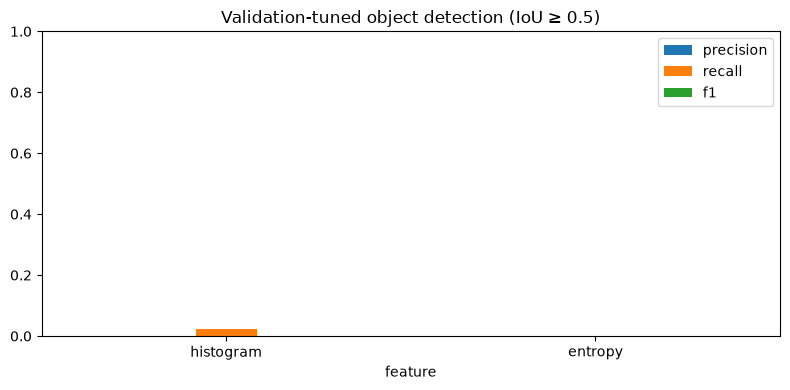

,total_seconds,seconds_per_image,fps,shared_extraction_seconds,matching_nms_seconds
histogram,18.2619,0.1522,6.5711,15.8234,2.4385
entropy,18.8516,0.1571,6.3655,15.8234,3.0283


,feature,fp
4,histogram,3280
11,entropy,0


In [3]:
overall=metrics[metrics.scope=='all'].set_index('feature')
overall[['precision','recall','f1']].plot.bar(figsize=(8,4),ylim=(0,1),rot=0)
plt.title('Validation-tuned object detection (IoU ≥ 0.5)');plt.tight_layout();plt.show()
display(pd.DataFrame(summary['speed']).T.round(4))
display(metrics[metrics.scope=='negative'][['feature','fp']])


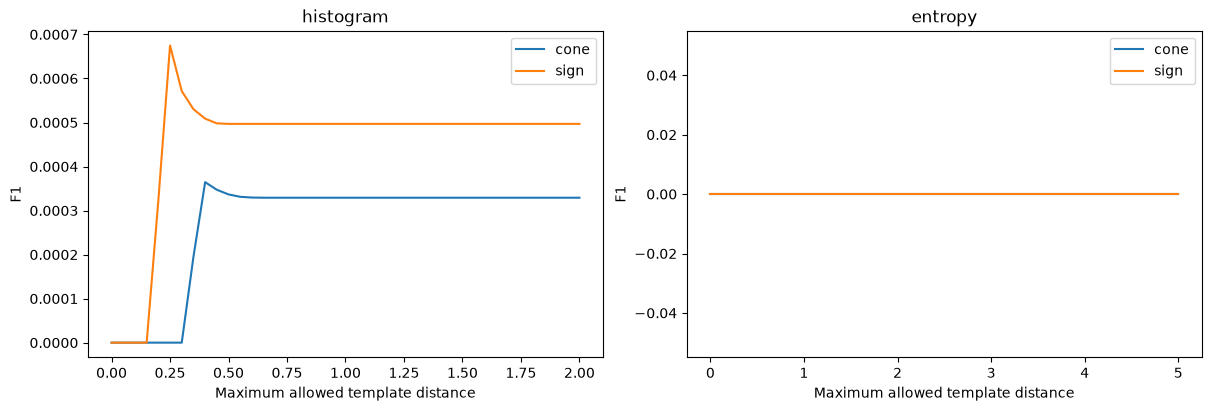

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for ax,feature in zip(axes,['histogram','entropy']):
    for cls in ['cone','sign']:
        subset=curves[(curves.feature==feature)&(curves.cls==cls)]
        ax.plot(subset.threshold,subset.f1,label=cls)
    ax.set(xlabel='Maximum allowed template distance',ylabel='F1',title=feature)
    ax.legend()
plt.show()


## Inspect detections and source boxes

Green dashed boxes are source annotations; red boxes are retained detector outputs after NMS and the selected threshold. Switch `IMAGE_INDEX` and `FEATURE`, then rerun. The optional `MAX_DISPLAY` limits only the plotted boxes; all detections are evaluated. The image stays grayscale. These images are diagnostic, not a substitute for the aggregate evaluation.


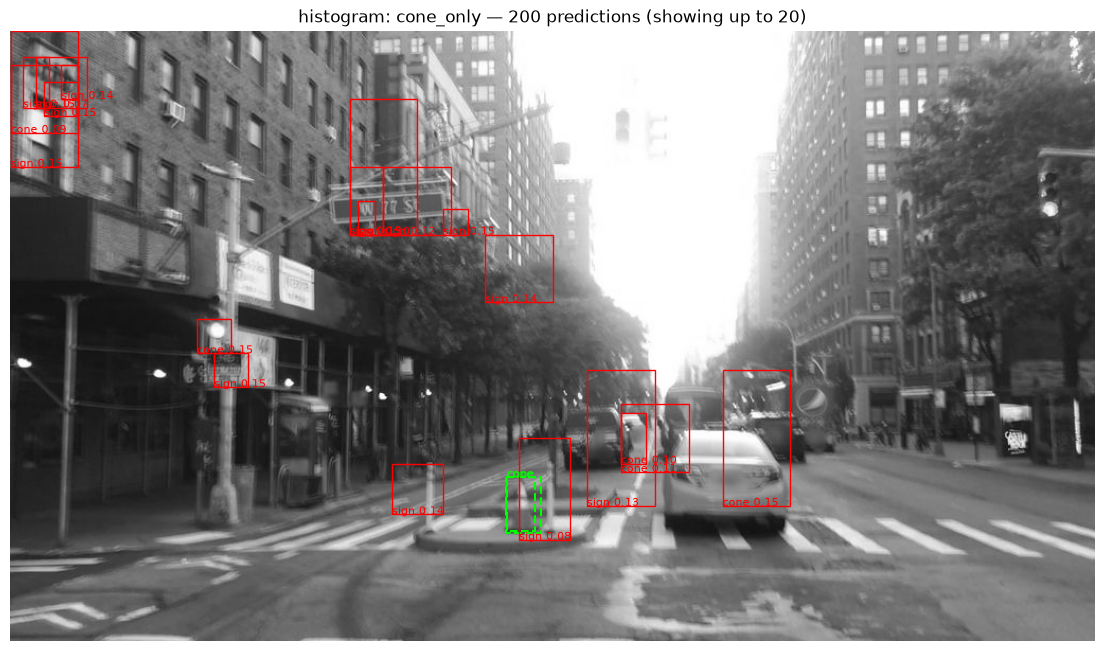

In [5]:
IMAGE_INDEX=0
FEATURE='histogram'
MAX_DISPLAY=20
metadata=pd.read_csv(PROJECT/'Test Dataset/validation/images.csv')
annotations=pd.read_csv(PROJECT/'Test Dataset/validation/annotations.csv')
image=metadata.iloc[IMAGE_INDEX]
with Image.open(PROJECT/'Test Dataset/validation'/image['image']) as im:
    gray=np.array(im.convert('L'))
fig,ax=plt.subplots(figsize=(14,9))
ax.imshow(gray,cmap='gray',vmin=0,vmax=255)
for _,r in annotations[annotations.image==image['image']].iterrows():
    if r.x1<=r.x0 or r.y1<=r.y0:continue
    ax.add_patch(Rectangle((r.x0,r.y0),r.x1-r.x0,r.y1-r.y0,fill=False,edgecolor='lime',linestyle='--',linewidth=1.5))
    ax.text(r.x0,r.y0,r['class'],color='lime',fontsize=8)
retained=[]
for cls in ['cone','sign']:
    for d in predictions[image['image']][FEATURE][cls]:
        if d['distance']<=summary['selected_thresholds'][FEATURE][cls]:retained.append(dict(d,cls=cls))
for d in sorted(retained,key=lambda d:d['distance'])[:MAX_DISPLAY]:
    x0,y0,x1,y1=d['box']
    ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,edgecolor='red',linewidth=1))
    ax.text(x0,y1,f"{d['cls']} {d['distance']:.2f}",color='red',fontsize=8)
ax.set_title(f"{FEATURE}: {image['group']} — {len(retained)} predictions (showing up to {MAX_DISPLAY})")
ax.axis('off');plt.show()


## Interpretation

A poor score is evidence about this specific baseline: class-average intensity templates, mask-only reference pixels, whole candidate windows and the stated distance/NMS settings. It does not prove every intensity method is ineffective. Entropy is only a brightness-diversity scalar and cannot by itself identify object shape or color. Use these results to decide the next development step; do not keep tuning on test. Freeze all choices before final held-out evaluation.
